# Regresja logistyczna – case study: Titanic

**Plan notatnika:**
1. Problem i dane
2. Wstępna analiza i braki danych
3. Przygotowanie danych i podział na zbiór treningowy i testowy
4. Model bazowy i regresja logistyczna
5. Ocena modelu
6. Interpretacja współczynników
7. Predykcja dla nowego pasażera
8. Podsumowanie

**Cel:** przewidzieć, czy pasażer Titanica **przeżył katastrofę**, na podstawie jego danych (klasa biletu, płeć, wiek itd.). To klasyczny problem klasyfikacji binarnej z konkursu Kaggle.

## 1. Problem i dane

Dane pochodzą z konkursu [Titanic – Machine Learning from Disaster](https://www.kaggle.com/competitions/titanic) i leżą w pliku `Titanic/train.csv` (891 pasażerów).

| Kolumna | Znaczenie |
|---|---|
| `Survived` | **zmienna celu**: 1 = przeżył, 0 = zginął |
| `Pclass` | klasa biletu (1 = najwyższa, 3 = najniższa) |
| `Name` | imię i nazwisko |
| `Sex` | płeć |
| `Age` | wiek w latach |
| `SibSp` | liczba rodzeństwa i małżonków na pokładzie |
| `Parch` | liczba rodziców i dzieci na pokładzie |
| `Ticket` | numer biletu |
| `Fare` | cena biletu |
| `Cabin` | numer kabiny |
| `Embarked` | port zaokrętowania (C = Cherbourg, Q = Queenstown, S = Southampton) |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('Titanic/train.csv')
df.head()

Bad value in file PosixPath('/Users/tomasz/.matplotlib/stylelib/company.mplstyle'), line 3 ("axes.prop_cycle: cycler('color', ['#123D98', '#C21E3C', '#E2A713', '#00AEEF', '#7F3F98'])"): Key axes.prop_cycle: "cycler('color', ['" is not a valid cycler construction: Could not parse "cycler('color', ['": unterminated string literal (detected at line 1) (<unknown>, line 1)
Bad value in file PosixPath('/Users/tomasz/.matplotlib/stylelib/company.mplstyle'), line 6 ('grid.color: #e0e0e0'): Key grid.color: '' does not look like a color arg


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 2. Wstępna analiza i braki danych

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [3]:
braki = df.isna().sum()
braki[braki > 0]

Age         177
Cabin       687
Embarked      2
dtype: int64

Braki występują w trzech kolumnach:
- `Age` – 177 braków (około 20%) – uzupełnimy **medianą**,
- `Embarked` – tylko 2 braki – uzupełnimy **najczęstszą wartością**,
- `Cabin` – większość wartości brakuje, więc **pomijamy** tę kolumnę.

Kolumn `PassengerId`, `Name` i `Ticket` nie użyjemy (to identyfikatory i tekst, które wymagałyby osobnej obróbki).

Zobaczmy, jak przeżywalność zależy od płci i klasy biletu:

In [4]:
print(f'Odsetek pasażerów, którzy przeżyli: {df["Survived"].mean():.3f}')

przezywalnosc = df.pivot_table(values='Survived', index='Pclass', columns='Sex', aggfunc='mean')
przezywalnosc.round(2)

Odsetek pasażerów, którzy przeżyli: 0.384


Sex,female,male
Pclass,,
1,0.97,0.37
2,0.92,0.16
3,0.50,0.14


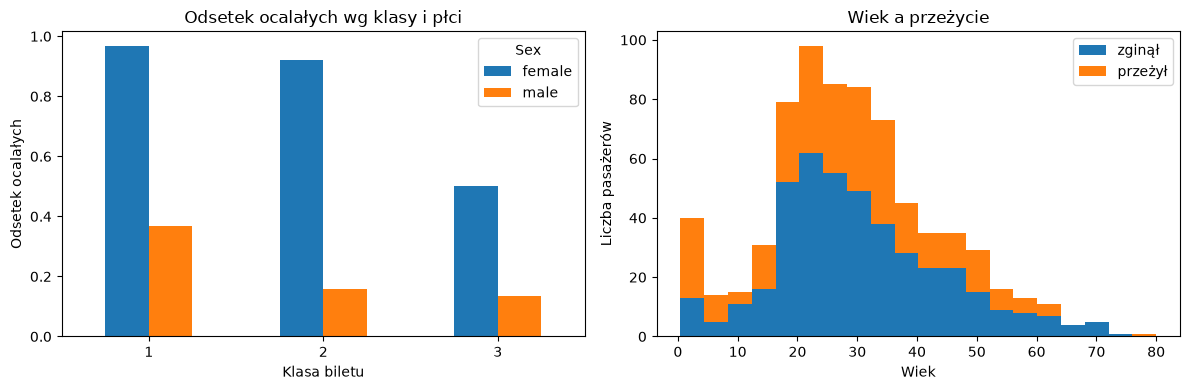

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

przezywalnosc.plot(kind='bar', ax=axes[0])
axes[0].set_title('Odsetek ocalałych wg klasy i płci')
axes[0].set_xlabel('Klasa biletu')
axes[0].set_ylabel('Odsetek ocalałych')
axes[0].tick_params(axis='x', rotation=0)

axes[1].hist([df.loc[df['Survived'] == 0, 'Age'].dropna(), df.loc[df['Survived'] == 1, 'Age'].dropna()],
             bins=20, stacked=True, label=['zginął', 'przeżył'])
axes[1].set_title('Wiek a przeżycie')
axes[1].set_xlabel('Wiek')
axes[1].set_ylabel('Liczba pasażerów')
axes[1].legend()

plt.tight_layout()
plt.show()

Wyraźnie widać, że **kobiety** i pasażerowie **pierwszej klasy** przeżywali znacznie częściej. Sprawdzimy, czy model potwierdzi te zależności.

## 3. Przygotowanie danych i podział na zbiór treningowy i testowy

Wybieramy cechy i dzielimy dane **przed** jakimkolwiek uzupełnianiem braków (żeby nie „podglądać” zbioru testowego). Braki uzupełnimy i zakodujemy cechy wewnątrz `Pipeline`, tak jak w rozdziale 2.4:

- cechy liczbowe: uzupełnienie medianą (`SimpleImputer`) + standaryzacja (`StandardScaler`),
- cechy kategoryczne: uzupełnienie najczęstszą wartością + kodowanie `OneHotEncoder` (cechy dwuwartościowe zamieniane na jedną kolumnę 0/1).

Klasa biletu `Pclass` jest zapisana liczbami 1, 2, 3, ale to **kategoria** (nie ma sensu mnożyć jej przez współczynnik), więc kodujemy ją jak cechę kategoryczną.

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

cechy_num = ['Age', 'SibSp', 'Parch', 'Fare']
cechy_kat = ['Pclass', 'Sex', 'Embarked']

X = df[cechy_num + cechy_kat]
y = df['Survived']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print('Zbiór treningowy:', X_train.shape, ' zbiór testowy:', X_test.shape)

Zbiór treningowy: (712, 7)  zbiór testowy: (179, 7)


In [7]:
przetwarzanie = ColumnTransformer([
    ('num', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), cechy_num),
    ('kat', make_pipeline(SimpleImputer(strategy='most_frequent'), OneHotEncoder(drop='if_binary')), cechy_kat),
])

model = Pipeline([
    ('przetwarzanie', przetwarzanie),
    ('regresja', LogisticRegression(max_iter=1000)),
])
model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('przetwarzanie', ...), ('regresja', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('kat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If

## 4. Model bazowy i regresja logistyczna

Najpierw **baseline** – `DummyClassifier`, który ignoruje cechy i zawsze przewiduje najczęstszą klasę (tu: „zginął”). Model musi być od niego lepszy.

In [8]:
from sklearn.dummy import DummyClassifier

dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train, y_train)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_score = model.predict_proba(X_test)[:, 1]
y_pred_dummy = dummy.predict(X_test)

## 5. Ocena modelu

In [9]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix, classification_report)

metryki = pd.DataFrame({
    'baseline (zawsze: zginął)': {
        'accuracy': accuracy_score(y_test, y_pred_dummy),
        'precision': precision_score(y_test, y_pred_dummy, zero_division=0),
        'recall': recall_score(y_test, y_pred_dummy),
        'F1': f1_score(y_test, y_pred_dummy),
        'ROC-AUC': 0.5,
    },
    'regresja logistyczna': {
        'accuracy': accuracy_score(y_test, y_pred),
        'precision': precision_score(y_test, y_pred),
        'recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_score),
    },
}).T

metryki.round(3)

,accuracy,precision,recall,F1,ROC-AUC
baseline (zawsze: zginął),0.615,0.000,0.000,0.000,0.500
regresja logistyczna,0.804,0.793,0.667,0.724,0.843


Baseline ma sporą accuracy tylko dlatego, że większość pasażerów zginęła, ale nie wykrywa żadnego ocalałego (recall = 0). Regresja logistyczna wyraźnie go pokonuje w każdej metryce.

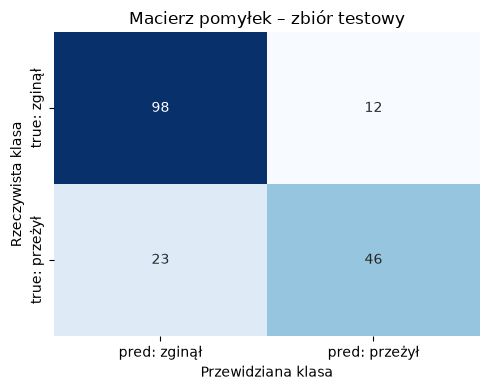

In [10]:
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['pred: zginął', 'pred: przeżył'], yticklabels=['true: zginął', 'true: przeżył'])
plt.xlabel('Przewidziana klasa')
plt.ylabel('Rzeczywista klasa')
plt.title('Macierz pomyłek – zbiór testowy')
plt.tight_layout()
plt.show()

In [11]:
print(classification_report(y_test, y_pred, target_names=['zginął (0)', 'przeżył (1)']))

              precision    recall  f1-score   support

  zginął (0)       0.81      0.89      0.85       110
 przeżył (1)       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



## 6. Interpretacja współczynników

Współczynniki to zmiany **log-odds**, a po przekształceniu funkcją $e^x$ – **ilorazy szans**:
- iloraz **większy od 1** – cecha zwiększa szansę przeżycia,
- iloraz **mniejszy od 1** – cecha zmniejsza szansę przeżycia.

Cechy liczbowe zostały standaryzowane, więc ich iloraz szans dotyczy wzrostu o **jedno odchylenie standardowe**. Dla cech kategorycznych (np. `Pclass_1`) iloraz opisuje przynależność do danej kategorii.

In [12]:
nazwy = model.named_steps['przetwarzanie'].get_feature_names_out()
wsp = model.named_steps['regresja'].coef_[0]

wspolczynniki = pd.DataFrame({
    'cecha': nazwy,
    'współczynnik': wsp,
    'iloraz szans (e^w)': np.exp(wsp),
}).sort_values('współczynnik', ascending=False).reset_index(drop=True)

wspolczynniki.round(3)

,cecha,współczynnik,iloraz szans (e^w)
0,kat__Pclass_1,0.987,2.684
1,kat__Embarked_Q,0.314,1.369
2,num__Fare,0.136,1.145
3,kat__Pclass_2,0.102,1.107
4,kat__Embarked_C,0.054,1.055
5,num__Parch,-0.064,0.938
6,num__SibSp,-0.258,0.773
7,kat__Embarked_S,-0.366,0.693
8,num__Age,-0.487,0.615
9,kat__Pclass_3,-1.087,0.337


Wnioski (liczby w tabeli powyżej):
- **płeć męska** (`Sex_male`) silnie obniża szanse przeżycia: iloraz szans wynosi około 0,08, czyli szanse mężczyzny są mniej więcej 13 razy niższe niż kobiety o pozostałych cechach takich samych,
- **pierwsza klasa** zwiększa szanse (iloraz około 2,7), a **trzecia** zmniejsza (iloraz około 0,34),
- starszy wiek (`Age`) obniża szanse przeżycia, co zgadza się z zasadą „kobiety i dzieci najpierw”,
- port zaokrętowania i cena biletu mają mniejsze znaczenie niż płeć i klasa (po uwzględnieniu pozostałych cech).

Pamiętajmy, że to zależności **statystyczne** – nie dowodzą przyczynowości.

## 7. Predykcja dla nowego pasażera

Model jest `Pipeline`, więc nowe dane podajemy w **surowej postaci** (z brakami włącznie) – uzupełnianie i kodowanie wykona się automatycznie.

In [13]:
nowi_pasazerowie = pd.DataFrame({
    'Age':      [30, 30, 8, 45],
    'SibSp':    [0, 0, 1, 0],
    'Parch':    [0, 0, 2, 0],
    'Fare':     [80.0, 8.0, 30.0, 15.0],
    'Pclass':   [1, 3, 2, 3],
    'Sex':      ['female', 'male', 'female', 'male'],
    'Embarked': ['S', 'S', 'C', 'Q'],
})

nowi_pasazerowie['P(przeżył)'] = model.predict_proba(nowi_pasazerowie)[:, 1].round(3)
nowi_pasazerowie['przewidywana klasa'] = model.predict(nowi_pasazerowie.drop(columns='P(przeżył)'))
nowi_pasazerowie

,Age,SibSp,Parch,Fare,Pclass,Sex,Embarked,P(przeżył),przewidywana klasa
0,30,0,0,80.0,1,female,S,0.921,1
1,30,0,0,8.0,3,male,S,0.085,0
2,8,1,2,30.0,2,female,C,0.906,1
3,45,0,0,15.0,3,male,Q,0.097,0


## 8. Podsumowanie

1. Zbudowaliśmy kompletny proces: **dane → podział → imputacja i kodowanie w `Pipeline` → regresja logistyczna → ocena → interpretacja**.
2. Model porównaliśmy z **baseline'em** (`DummyClassifier`) – dzięki temu wiemy, że faktycznie coś się nauczył.
3. Współczynniki regresji logistycznej dają się **interpretować** jako ilorazy szans – to jej główna zaleta w porównaniu z bardziej złożonymi modelami.
4. Wynik policzony na jednym podziale może zależeć od wylosowanego zbioru testowego. Stabilniejszą ocenę da **walidacja krzyżowa** (rozdział 4.4), a lepsze dopasowanie – inne modele (drzewa decyzyjne w rozdziale 4.1, las losowy w 4.2).